In [7]:
lod = 0.2063 * 0.63/3
IWA = 3 * lod
OWA = 20 * lod
OWA10 = 10 * lod
cmin = 1e-7
cgoal = 2e-9

def GetCLevels(arr, sigmas = [1,2,3], nlevels = None):
    Hflat = arr.flatten()
    inds = np.argsort(Hflat)[::-1]
    Hflat = Hflat[inds]
    sm = np.cumsum(Hflat)
    sm /= sm[-1]
    print(Hflat.min(),Hflat.max())
    if not nlevels:
        levels = 1.0 - np.exp(-0.5 * np.array(sigmas) ** 2)
    else:
        # from matplotlib.ticker import MaxNLocator
        # levels = MaxNLocator(nbins=nlevels).tick_values(Hflat.min(), Hflat.max())
        levels = np.linspace(H.min(), H.max(), nlevels)
    print(levels)
    V = np.empty(len(levels))
    for i, v0 in enumerate(levels):
        try:
            V[i] = Hflat[sm <= v0][-1]
        except IndexError:
            V[i] = Hflat[0]
    clevels = np.sort(V)
    return clevels

from scipy.ndimage import gaussian_filter
def GetHist(xx,yy, sigmas = [1,2], nlevels = None):
    ''' For arrays xx and yy, generate a 2d histogram and values for plotting contours
    '''
    H, xe,ye = np.histogram2d(xx, yy, bins=(100,100))
    Hflat = H.flatten()
    inds = np.argsort(Hflat)[::-1]
    Hflat = Hflat[inds]
    sm = np.cumsum(Hflat)
    sm /= sm[-1]
    
    if not nlevels:
        levels = 1.0 - np.exp(-0.5 * np.array(sigmas) ** 2)
    else:
        from matplotlib.ticker import MaxNLocator
        levels = MaxNLocator(nbins=nlevels).tick_values(Hflat.min(), Hflat.max())
    V = np.empty(len(levels))
    for i, v0 in enumerate(levels):
        try:
            V[i] = Hflat[sm <= v0][-1]
        except IndexError:
            V[i] = Hflat[0]
    midpoints = (xe[1:] + xe[:-1])/2, (ye[1:] + ye[:-1])/2
    return H, xe, ye, midpoints, np.sort(V)

In [2]:
OWA

0.86646

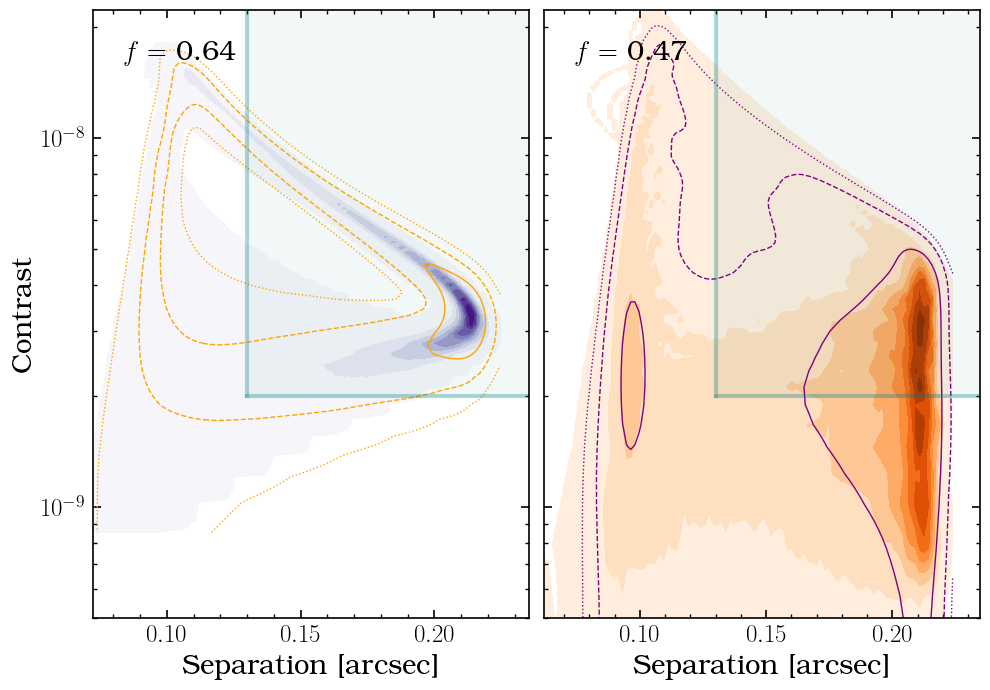

In [8]:
sepsarrDict,contsarrDict = pickle.load(open('../14Herb-sep-cont-sim.pkl','rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.5,'all']
cmaps = ['Purples','Oranges']
import matplotlib

for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict[Ag[i]].flatten()
    contsarr = contsarrDict[Ag[i]].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 10
    levels = np.linspace(1, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    # ax.plot([IWA,OWA],[cmin,cmin], color='black')
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA10,OWA10],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.2,0.95), xycoords='axes fraction', fontsize=20, ha='center', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('14Herb-completeness.png', bbox_inches='tight')

In [47]:
(0.2063*0.4/3)*10

0.2750666666666667

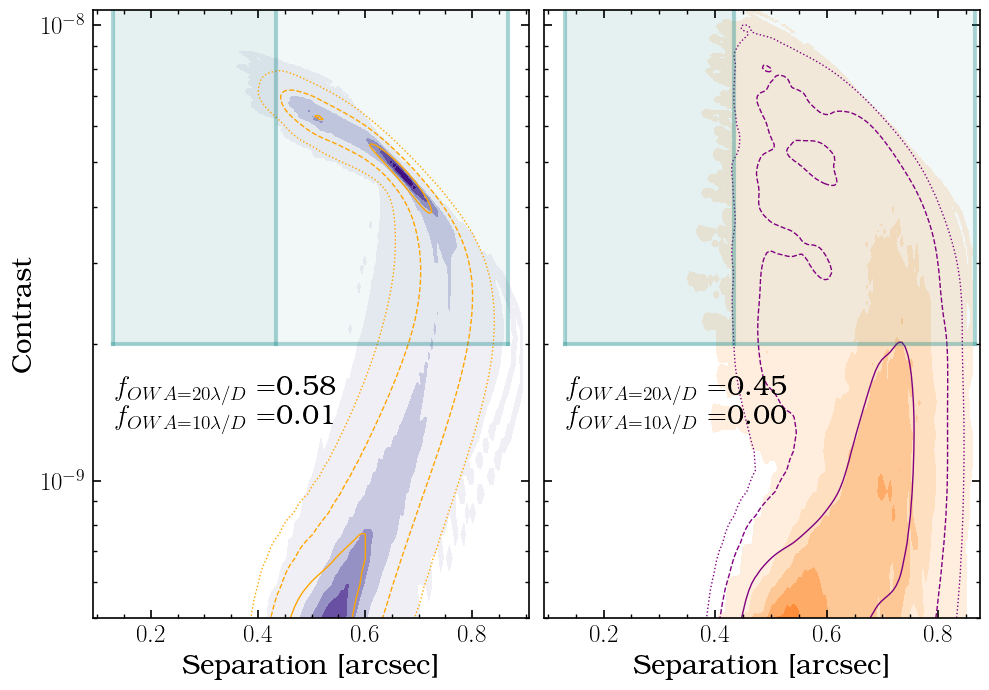

In [45]:
sepsarrDict,contsarrDict = pickle.load(open('../GJ832b-sep-cont-sim.pkl','rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.5,'all']
cmaps = ['Purples','Oranges']
import matplotlib
norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict[Ag[i]].flatten()
    contsarr = contsarrDict[Ag[i]].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    compl10 = np.where((sepsarr > IWA) & (sepsarr < OWA10) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 10
    levels = np.linspace(1, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    ax.fill_between([IWA,OWA10], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA10,OWA10],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f_{OWA=20\\lambda/D}=$'+'{:.2f}'.format(compl), xy = (0.05,0.4), xycoords='axes fraction', fontsize=20, ha='left', va='top')
    ax.annotate('$f_{OWA=10\\lambda/D}=$'+'{:.2f}'.format(compl10), xy = (0.05,0.35), xycoords='axes fraction', fontsize=20, ha='left', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('GJ832b-completeness.png', bbox_inches='tight')

In [21]:
planetsinc = [
    '14 Her b','GJ 832 b','HD 114783 c', 'HD 190360 b', 'bet Pic b', 'HD 154345 b', 'HD 87883 b', 'pi Men b',
    'HD 75302 b', 'bet Pic c', 'eps Eri b'
]
len(planetsinc)

11

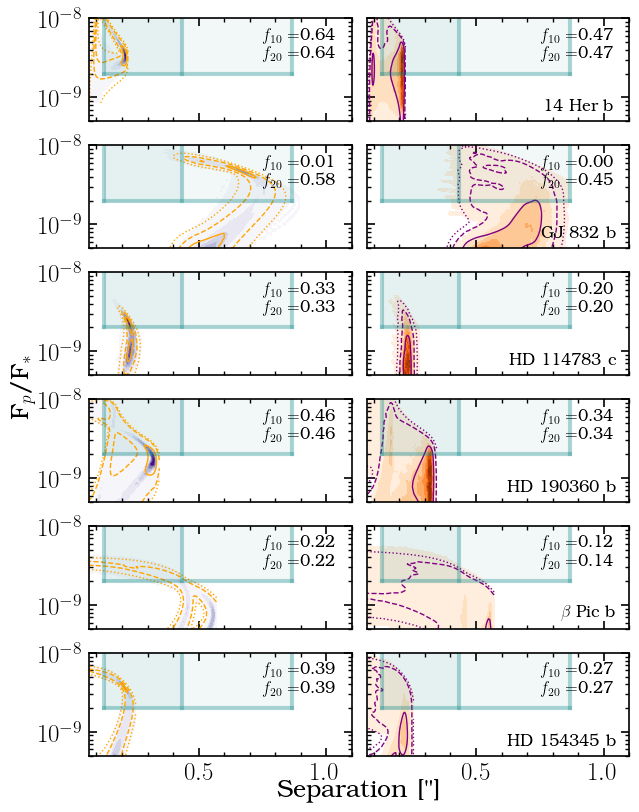

In [35]:



fig,axes = plt.subplots(nrows=6, ncols=2, figsize=(7,8.5), sharey=True, sharex = True)
linestyles=[':','--','-']
Ag = [0.5,'all']
cmaps = ['Purples','Oranges']
import matplotlib


for j in range(6):

    sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format(planetsinc[j].replace(' ','')),'rb'))
    axes1 = axes[j,:]
    
    for i,ax in enumerate(axes1.flatten()):
        cmap = cmaps[i]
        if i == 0:
            color = 'orange'
        elif i == 1:
            color = 'purple'
        sepsarr = sepsarrDict[Ag[i]].flatten()
        contsarr = contsarrDict[Ag[i]].flatten()
        compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        compl10 = np.where((sepsarr > IWA) & (sepsarr < OWA10) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
        norm = matplotlib.colors.Normalize(vmin = np.min(H.T),vmax = np.max(H.T))
        #ax.pcolormesh(xbins, ybins, H.T)
        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        nlevels = 10
        levels = np.linspace(1, H.max(), nlevels)
        CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                                )
        CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                                linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
        ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
        ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([OWA10,OWA10],[cgoal,cmin], color='teal',alpha=0.3)
        # ax.plot([IWA,OWA],[cmin,cmin], color='black')
        ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.fill_between([IWA,OWA10], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.set_yscale('log')
        ax.set_ylim(top=max(yedges), bottom=5e-10)
        ax.set_xlim(right=max(sepsarr)+0.01)
        # if i == 0:
        #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        # if i == 1:
        #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        fontsize=12
        # if i == 0:
        #     ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='right', va='center')
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.7), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        # elif i == 1:
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        ax.annotate('$f_{10}=$'+'{:.2f}'.format(compl10), xy = (0.8,0.83), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
        ax.annotate('$f_{20}=$'+'{:.2f}'.format(compl), xy = (0.8,0.65), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
        if i == 1:
            ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.15), xycoords='axes fraction', 
                         fontsize=fontsize, ha='right', va='center')
            

        ax.set_xlim(right=1.1)
        ax.set_ylim(5e-10,1e-8)

bigax = fig.add_subplot(111, frameon=False)
bigax.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
bigax.set_xticks([], minor=True)
bigax.set_yticks([], minor=True)
bigax.set_ylabel('F$_p$/F$_*$', fontsize=18)
bigax.yaxis.set_label_coords(-0.1, 0.5)
bigax.set_xlabel('Separation ["]', fontsize=18)
bigax.xaxis.set_label_coords(0.5, -0.03)

plt.tight_layout()
plt.savefig('inc-targets-sep-cont-1.png',bbox_inches='tight')

In [26]:
bbox = ax.get_position()
fig_w, fig_h = fig.get_size_inches()
# 3. Convert the relative fractions into absolute inches
x0_inch = bbox.x0 * fig_w          # Left edge distance from bottom-left
y0_inch = bbox.y0 * fig_h          # Bottom edge distance from bottom-left
width_inch = bbox.width * fig_w    # Width of the axis in inches
height_inch = bbox.height * fig_h  # Height of the axis in inches

print(f"Position (Left, Bottom) in inches: ({x0_inch:.3f}, {y0_inch:.3f})")
print(f"Dimensions (Width x Height) in inches: {width_inch:.3f} x {height_inch:.3f}")


Position (Left, Bottom) in inches: (4.226, 0.887)
Dimensions (Width x Height) in inches: 2.624 x 1.028


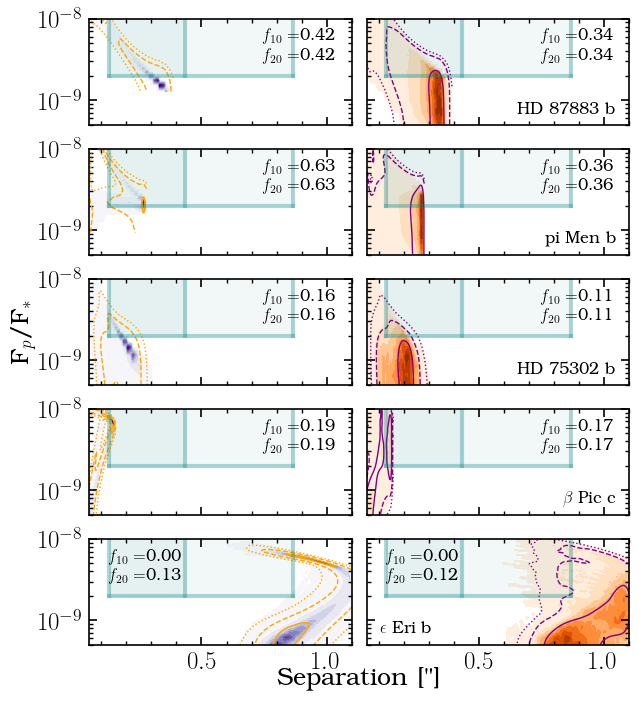

In [36]:



fig,axes = plt.subplots(nrows=5, ncols=2, figsize=(7,8.5-1.108), sharey=True, sharex = True)
linestyles=[':','--','-']
Ag = [0.5,'all']
cmaps = ['Purples','Oranges']
import matplotlib


for k,j in enumerate(range(6,len(planetsinc))):

    sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format(planetsinc[j].replace(' ','')),'rb'))
    axes1 = axes[k,:]
    
    for i,ax in enumerate(axes1.flatten()):
        cmap = cmaps[i]
        if i == 0:
            color = 'orange'
        elif i == 1:
            color = 'purple'
        sepsarr = sepsarrDict[Ag[i]].flatten()
        contsarr = contsarrDict[Ag[i]].flatten()
        compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        compl10 = np.where((sepsarr > IWA) & (sepsarr < OWA10) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
        norm = matplotlib.colors.Normalize(vmin = np.min(H.T),vmax = np.max(H.T))
        #ax.pcolormesh(xbins, ybins, H.T)
        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        nlevels = 10
        levels = np.linspace(1, H.max(), nlevels)
        CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                                )
        CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                                linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
        ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
        ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([OWA10,OWA10],[cgoal,cmin], color='teal',alpha=0.3)
        # ax.plot([IWA,OWA],[cmin,cmin], color='black')
        ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.fill_between([IWA,OWA10], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.set_yscale('log')
        ax.set_ylim(top=max(yedges), bottom=5e-10)
        ax.set_xlim(right=max(sepsarr)+0.01)
        # if i == 0:
        #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        # if i == 1:
        #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        fontsize=12
        # if i == 0:
        #     ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='right', va='center')
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.7), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        # elif i == 1:
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        if j == 10:
            ax.annotate('$f_{10}=$'+'{:.2f}'.format(compl10), xy = (0.07,0.83), xycoords='axes fraction', 
                         fontsize=fontsize, ha='left', va='center')
            ax.annotate('$f_{20}=$'+'{:.2f}'.format(compl), xy = (0.07,0.65), xycoords='axes fraction', 
                         fontsize=fontsize, ha='left', va='center')
            if i == 1:
                ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$').replace('pi','$\\pi$').replace('eps','$\\epsilon$')),
                            xy = (0.05,0.15), xycoords='axes fraction', 
                             fontsize=fontsize, ha='left', va='center')
        else:
            ax.annotate('$f_{10}=$'+'{:.2f}'.format(compl10), xy = (0.8,0.83), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
            ax.annotate('$f_{20}=$'+'{:.2f}'.format(compl), xy = (0.8,0.65), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
            if i == 1:
                ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.15), xycoords='axes fraction', 
                             fontsize=fontsize, ha='right', va='center')
            

        ax.set_xlim(right=1.1)
        ax.set_ylim(5e-10,1e-8)

bigax = fig.add_subplot(111, frameon=False)
bigax.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
bigax.set_xticks([], minor=True)
bigax.set_yticks([], minor=True)
bigax.set_ylabel('F$_p$/F$_*$', fontsize=18)
bigax.yaxis.set_label_coords(-0.1, 0.5)
bigax.set_xlabel('Separation ["]', fontsize=18)
bigax.xaxis.set_label_coords(0.5, -0.035)

plt.tight_layout()
plt.savefig('inc-targets-sep-cont-2.png',bbox_inches='tight')

# No incl

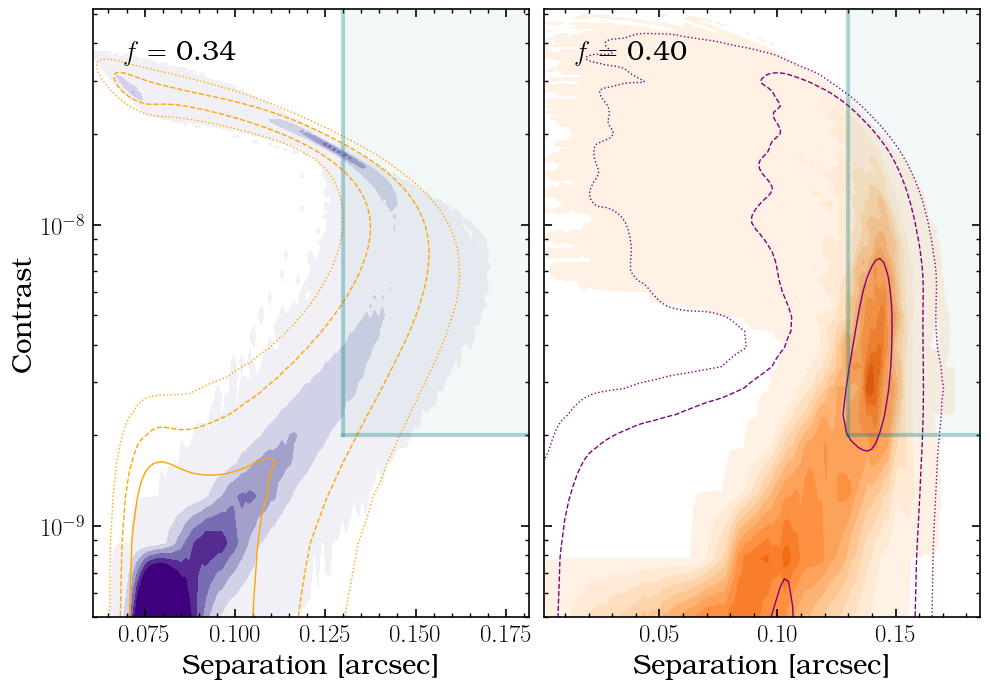

In [42]:
sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format('gammaCepb'),'rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.5,'all']
incl = [60, np.nan]
cmaps = ['Purples','Oranges']
import matplotlib
norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 15
    levels = np.linspace(1, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    # ax.plot([IWA,OWA],[cmin,cmin], color='black')
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.2,0.95), xycoords='axes fraction', fontsize=20, ha='center', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('gammaCepb-completeness.png', bbox_inches='tight')

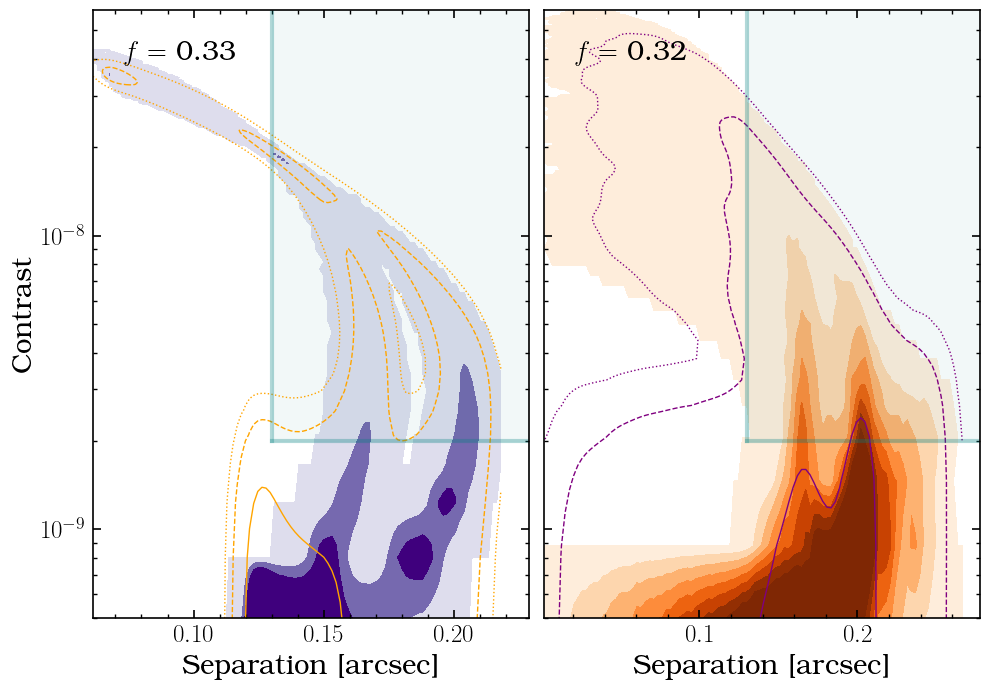

In [43]:
sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format('upsAndd'),'rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.5,'all']
incl = [60, np.nan]
cmaps = ['Purples','Oranges']
import matplotlib
norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 15
    levels = np.linspace(0.01, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    # ax.plot([IWA,OWA],[cmin,cmin], color='black')
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.2,0.95), xycoords='axes fraction', fontsize=20, ha='center', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('upsAndd-completeness.png', bbox_inches='tight')

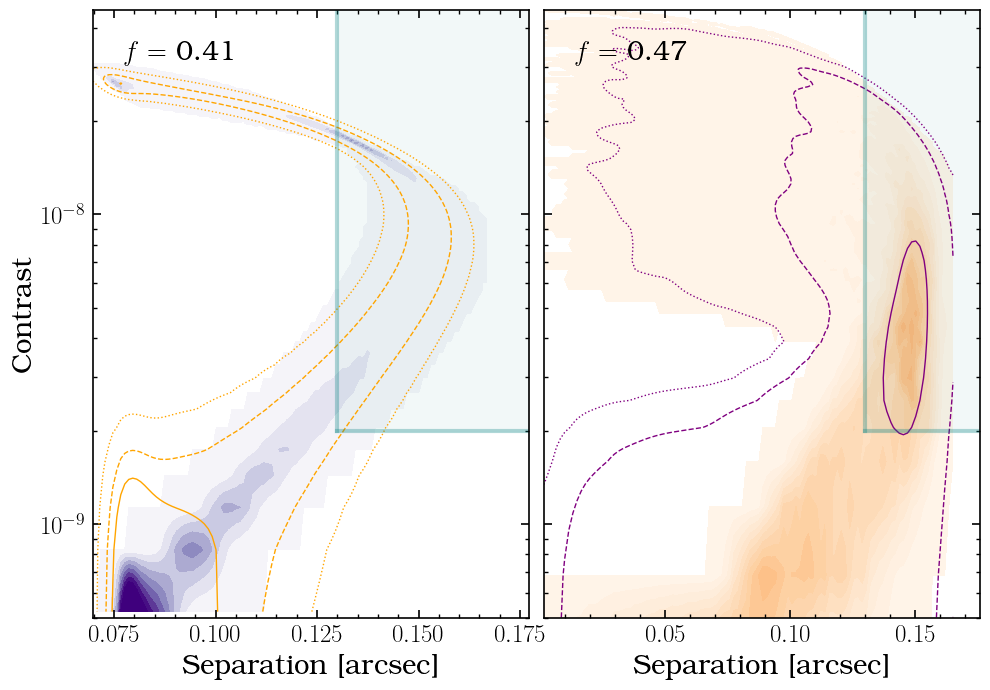

In [33]:
sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format('47UMab'),'rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.5,'all']
incl = [60, np.nan]
cmaps = ['Purples','Oranges']
import matplotlib
norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 15
    levels = np.linspace(0.01, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    # ax.plot([IWA,OWA],[cmin,cmin], color='black')
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.2,0.95), xycoords='axes fraction', fontsize=20, ha='center', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('47UMab-completeness.png', bbox_inches='tight')

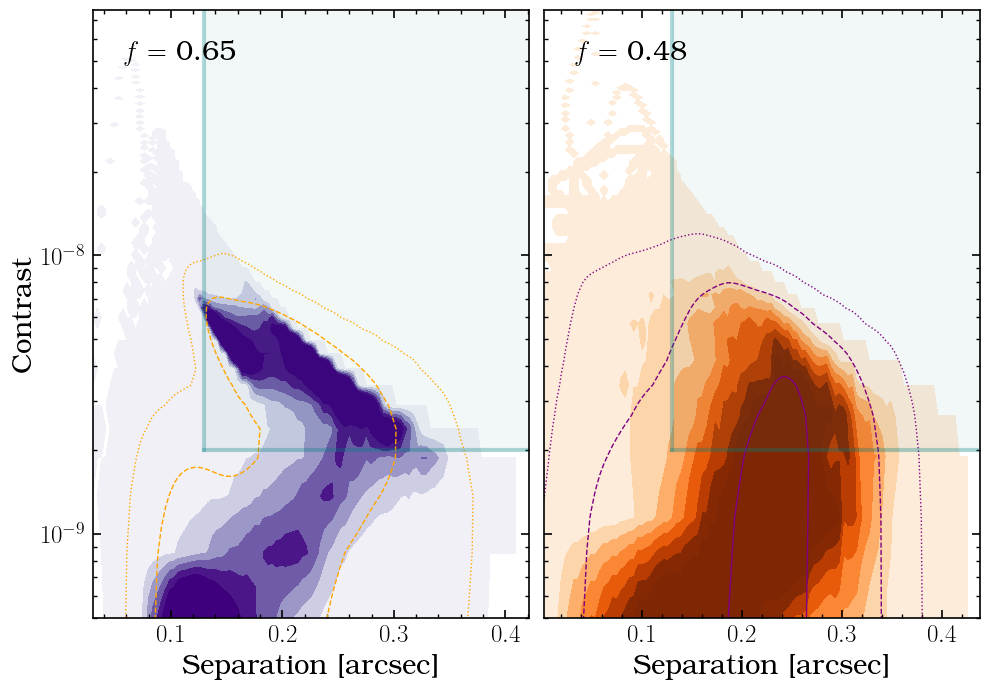

In [121]:
sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format('47UMac'),'rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.45,'all']
incl = [60, np.nan]
cmaps = ['Purples','Oranges']
import matplotlib
norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 15
    levels = np.linspace(0.01, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    # ax.plot([IWA,OWA],[cmin,cmin], color='black')
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.2,0.95), xycoords='axes fraction', fontsize=20, ha='center', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('47UMac-completeness.png', bbox_inches='tight')

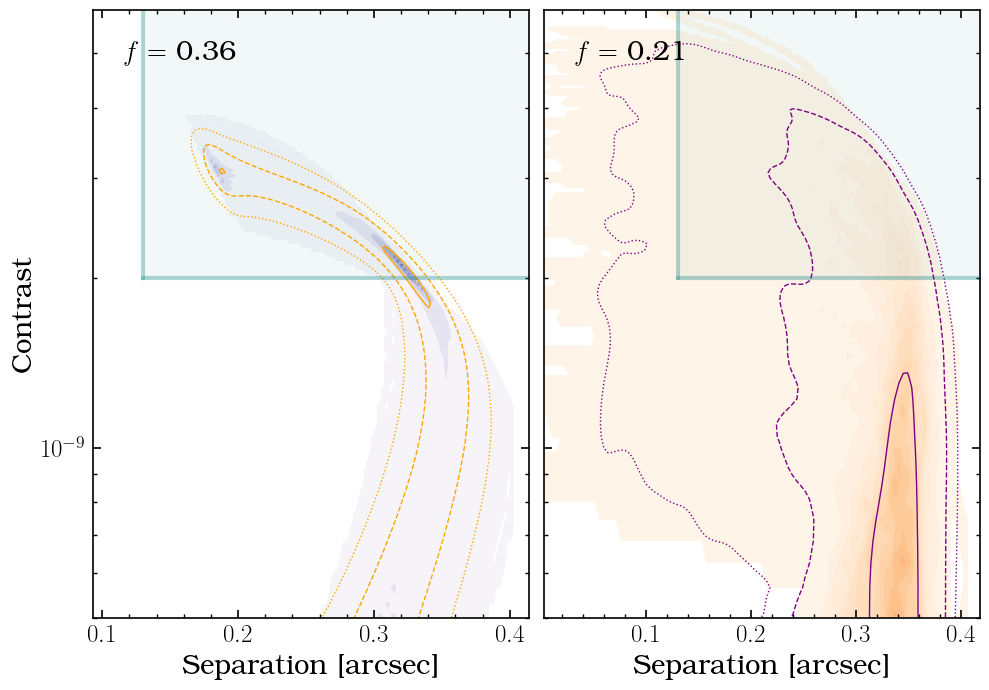

In [122]:
sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format('HD160691c'),'rb'))

fig,axes = plt.subplots(nrows=1, ncols=2, figsize=(10,7), sharey=True)
linestyles=[':','--','-']
Ag = [0.45,'all']
incl = [60, np.nan]
cmaps = ['Purples','Oranges']
import matplotlib
norm = matplotlib.colors.Normalize(vmin = 0,vmax = np.max(H.T))
for i,ax in enumerate(axes.flatten()):
    cmap = cmaps[i]
    if i == 0:
        color = 'orange'
    elif i == 1:
        color = 'purple'
    sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
    compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
    H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
    #ax.pcolormesh(xbins, ybins, H.T)
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    nlevels = 15
    levels = np.linspace(0.01, H.max(), nlevels)
    CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                            )
    CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                            linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
    # ax.plot([IWA,OWA],[cmin,cmin], color='black')
    ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
    ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
    ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
    ax.set_yscale('log')
    ax.set_ylim(top=max(yedges), bottom=5e-10)
    ax.set_xlim(right=max(sepsarr)+0.01)
    # if i == 0:
    #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    # if i == 1:
    #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
    ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.2,0.95), xycoords='axes fraction', fontsize=20, ha='center', va='top')
    if i == 0:
        ax.set_ylabel('Contrast')
    if i == 0 or i == 1:
        ax.set_xlabel('Separation [arcsec]')
plt.tight_layout()
plt.savefig('HD160691cc-completeness.png', bbox_inches='tight')

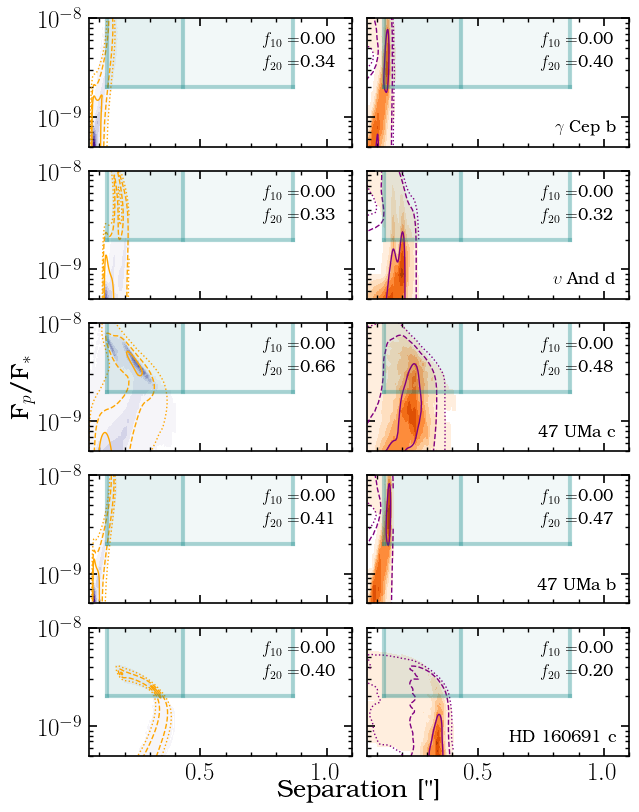

In [37]:
planetsnoinc = [
    'gamma Cep b', 'ups And d', '47 UMa c', '47 UMa b', 'HD 160691 c'
]




fig,axes = plt.subplots(nrows=5, ncols=2, figsize=(7,8.5), sharey=True, sharex = True)
linestyles=[':','--','-']
Ag = [0.5,'all']
incl = [60, np.nan]
cmaps = ['Purples','Oranges']
import matplotlib


for j in range(5):

    sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format(planetsnoinc[j].replace(' ','')),'rb'))
    axes1 = axes[j,:]
    
    for i,ax in enumerate(axes1.flatten()):
        cmap = cmaps[i]
        if i == 0:
            color = 'orange'
        elif i == 1:
            color = 'purple'
        sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
        contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
        compl = np.where((sepsarr > IWA) & (sepsarr < OWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        compl = np.where((sepsarr > IWA) & (sepsarr < OWA10) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
        norm = matplotlib.colors.Normalize(vmin = np.min(H.T),vmax = np.max(H.T))
        #ax.pcolormesh(xbins, ybins, H.T)
        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        nlevels = 10
        levels = np.linspace(1, H.max(), nlevels)
        CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                                )
        CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                                linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
        ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.3)
        ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([OWA10,OWA10],[cgoal,cmin], color='teal',alpha=0.3)
        # ax.plot([IWA,OWA],[cmin,cmin], color='black')
        ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.fill_between([IWA,OWA10], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.set_yscale('log')
        ax.set_ylim(top=max(yedges), bottom=5e-10)
        ax.set_xlim(right=max(sepsarr)+0.01)
        # if i == 0:
        #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        # if i == 1:
        #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        fontsize=12
        # if i == 0:
        #     ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='right', va='center')
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.7), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        # elif i == 1:
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        ax.annotate('$f_{10}=$'+'{:.2f}'.format(compl10), xy = (0.8,0.83), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
        ax.annotate('$f_{20}=$'+'{:.2f}'.format(compl), xy = (0.8,0.65), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
        if i == 1:
            ax.annotate('{}'.format(planetsnoinc[j].replace('gamma','$\\gamma$').replace('ups','$\\upsilon$')), 
                        xy = (0.95,0.15), xycoords='axes fraction', 
                         fontsize=fontsize, ha='right', va='center')
            

        ax.set_xlim(right=1.1)
        ax.set_ylim(5e-10,1e-8)

bigax = fig.add_subplot(111, frameon=False)
bigax.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
bigax.set_xticks([], minor=True)
bigax.set_yticks([], minor=True)
bigax.set_ylabel('F$_p$/F$_*$', fontsize=18)
bigax.yaxis.set_label_coords(-0.1, 0.5)
bigax.set_xlabel('Separation ["]', fontsize=18)
bigax.xaxis.set_label_coords(0.5, -0.03)

plt.tight_layout()
plt.savefig('noinc-targets-sep-cont-1.png',bbox_inches='tight')

In [39]:
blueIWA = 3*0.2063*0.4/3
blueOWA = 20*0.2063*0.4/3


HD 219134 h dict_keys(['Ag0.5inc60', 'Agallincnan'])
HD 160691 b dict_keys(['Ag0.5inc60', 'Agallincnan'])
7 CMa c dict_keys(['Ag0.5inc60', 'Agallincnan'])
7 CMa b dict_keys(['Ag0.5inc60', 'Agallincnan'])
HD 10647 b dict_keys(['Ag0.5inc60', 'Agallincnan'])
HD 192310 c dict_keys(['Ag0.5inc60', 'Agallincnan'])


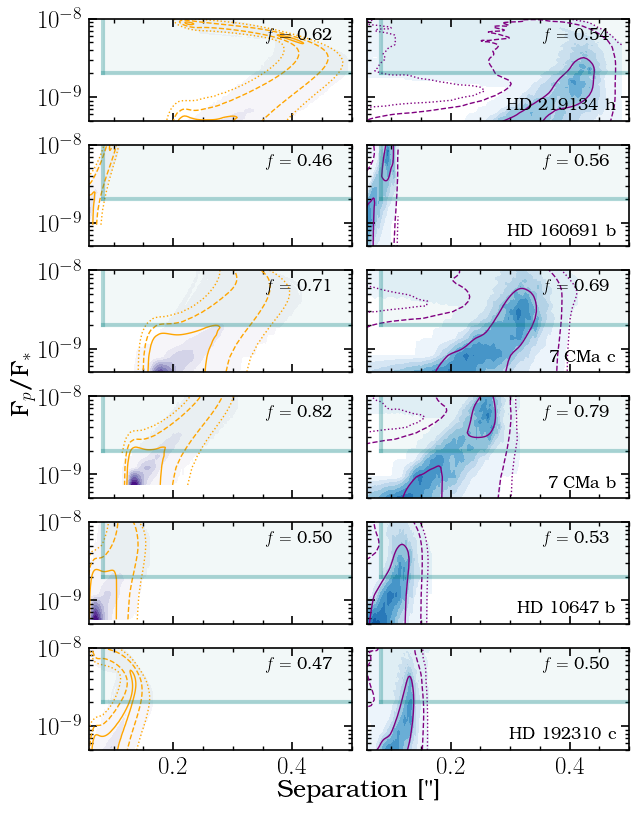

In [40]:
planetsblue = ['HD 219134 h', 'HD 160691 b', '7 CMa c', '7 CMa b', 'HD 10647 b', 'HD 192310 c', 'HD 192310 c',
              'HD 216437 b', 'HD 164922 b', 'HD 70642 b', 'psi1 Dra B b', 'HD 128311 c']


fig,axes = plt.subplots(nrows=6, ncols=2, figsize=(7,8.5), sharey=True, sharex = True)
linestyles=[':','--','-']
Ag = [0.5,'all']
incl = [60, np.nan]
cmaps = ['Purples','Blues']
import matplotlib


for j in range(6):

    sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format(planetsblue[j].replace(' ','')),'rb'))
    axes1 = axes[j,:]
    print(planetsblue[j],sepsarrDict.keys())
    
    for i,ax in enumerate(axes1.flatten()):
        cmap = cmaps[i]
        if i == 0:
            color = 'orange'
        elif i == 1:
            color = 'purple'
        try:
            sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
            contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
        except KeyError:
            sepsarr = sepsarrDict[Ag[i]].flatten()
            contsarr = contsarrDict[Ag[i]].flatten()
            
        compl = np.where((sepsarr > blueIWA) & (sepsarr < blueOWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
        norm = matplotlib.colors.Normalize(vmin = np.min(H.T),vmax = np.max(H.T))
        #ax.pcolormesh(xbins, ybins, H.T)
        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        nlevels = 10
        levels = np.linspace(1, H.max(), nlevels)
        CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                                )
        CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                                linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
        ax.plot([blueIWA,blueOWA],[cgoal,cgoal], color='teal',alpha=0.3)
        ax.plot([blueIWA,blueIWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([blueOWA,blueOWA],[cgoal,cmin], color='teal',alpha=0.3)
        # ax.plot([IWA,OWA],[cmin,cmin], color='black')
        ax.fill_between([blueIWA,blueOWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.set_yscale('log')
        ax.set_ylim(top=max(yedges), bottom=5e-10)
        ax.set_xlim(right=max(sepsarr)+0.01)
        # if i == 0:
        #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        # if i == 1:
        #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        fontsize=12
        # if i == 0:
        #     ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='right', va='center')
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.7), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        # elif i == 1:
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.83), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
        if i == 1:
            ax.annotate('{}'.format(planetsblue[j].replace('gamma','$\\gamma$').replace('ups','$\\upsilon$')), 
                        xy = (0.95,0.15), xycoords='axes fraction', 
                         fontsize=fontsize, ha='right', va='center')
            

        ax.set_xlim(right=0.5)
        ax.set_ylim(5e-10,1e-8)

bigax = fig.add_subplot(111, frameon=False)
bigax.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
bigax.set_xticks([], minor=True)
bigax.set_yticks([], minor=True)
bigax.set_ylabel('F$_p$/F$_*$', fontsize=18)
bigax.yaxis.set_label_coords(-0.1, 0.5)
bigax.set_xlabel('Separation ["]', fontsize=18)
bigax.xaxis.set_label_coords(0.5, -0.04)

plt.tight_layout()
plt.savefig('blue-targets-sep-cont-1.png',bbox_inches='tight')

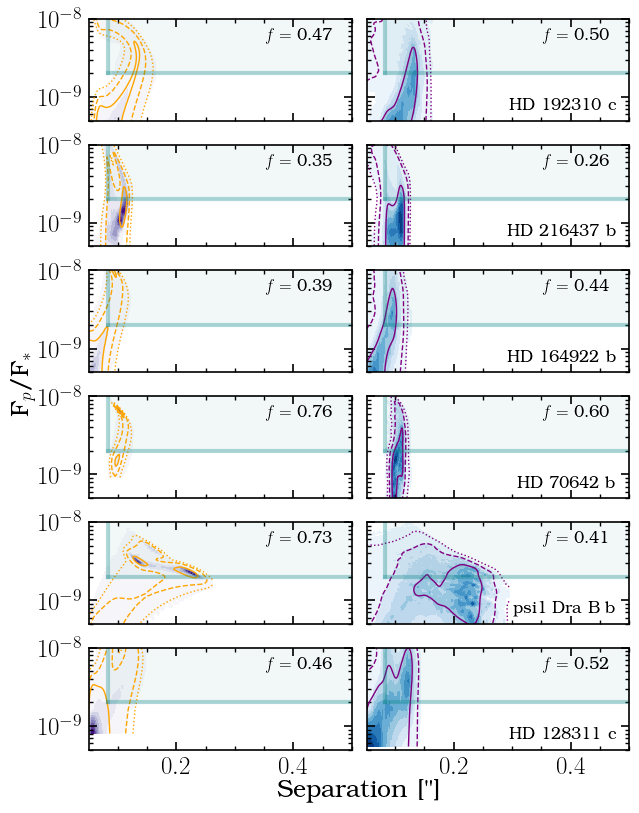

In [41]:

planetsblue = ['HD 219134 h', 'HD 160691 b', '7 CMa c', '7 CMa b', 'HD 10647 b', 'HD 192310 c', 'HD 192310 c',
              'HD 216437 b', 'HD 164922 b', 'HD 70642 b', 'psi1 Dra B b', 'HD 128311 c']


fig,axes = plt.subplots(nrows=6, ncols=2, figsize=(7,8.5), sharey=True, sharex = True)
linestyles=[':','--','-']
Ag = [0.5,'all']
incl = [60, np.nan]
cmaps = ['Purples','Blues']
import matplotlib


for k,j in enumerate(range(6,len(planetsblue))):

    sepsarrDict,contsarrDict = pickle.load(open('../{}-sep-cont-sim.pkl'.format(planetsblue[j].replace(' ','')),'rb'))
    axes1 = axes[k,:]
    
    
    for i,ax in enumerate(axes1.flatten()):
        cmap = cmaps[i]
        if i == 0:
            color = 'orange'
        elif i == 1:
            color = 'purple'
        try:
            sepsarr = sepsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
            contsarr = contsarrDict['Ag{}inc{}'.format(Ag[i],incl[i])].flatten()
        except KeyError:
            sepsarr = sepsarrDict[Ag[i]].flatten()
            contsarr = contsarrDict[Ag[i]].flatten()
            
        compl = np.where((sepsarr > blueIWA) & (sepsarr < blueOWA) & (contsarr > cgoal))[0].shape[0] / sepsarr.shape[0]
        H, xedges, yedges, midpoints, clevels = GetHist(sepsarr,contsarr, sigmas = [1,2,3])
        norm = matplotlib.colors.Normalize(vmin = np.min(H.T),vmax = np.max(H.T))
        #ax.pcolormesh(xbins, ybins, H.T)
        xc = 0.5 * (xedges[:-1] + xedges[1:])
        yc = 0.5 * (yedges[:-1] + yedges[1:])
        nlevels = 10
        levels = np.linspace(1, H.max(), nlevels)
        CS1 = ax.contourf(xc,yc, H.T, levels = levels, vmin=1, cmap=cmap, norm=norm
                                )
        CS1 = ax.contour(xc,yc,gaussian_filter(H.T, sigma=2), levels = clevels, 
                                linewidths=1, linestyles = linestyles, colors=[color]*len(linestyles))
        ax.plot([blueIWA,blueOWA],[cgoal,cgoal], color='teal',alpha=0.3)
        ax.plot([blueIWA,blueIWA],[cgoal,cmin], color='teal',alpha=0.3)
        ax.plot([blueOWA,blueOWA],[cgoal,cmin], color='teal',alpha=0.3)
        # ax.plot([IWA,OWA],[cmin,cmin], color='black')
        ax.fill_between([blueIWA,blueOWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.05)
        ax.set_yscale('log')
        ax.set_ylim(top=max(yedges), bottom=5e-10)
        ax.set_xlim(right=max(sepsarr)+0.01)
        # if i == 0:
        #     ax.annotate('Ag = '+str(Ag[i]), xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        # if i == 1:
        #     ax.annotate('Ag = 0.1 - 0.7', xy = (0.2,0.15), xycoords='axes fraction', fontsize=15, ha='center')
        fontsize=12
        # if i == 0:
        #     ax.annotate('{}'.format(planetsinc[j].replace('bet','$\\beta$')), xy = (0.95,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='right', va='center')
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.7), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        # elif i == 1:
        #     ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.85), xycoords='axes fraction', 
        #                 fontsize=fontsize, ha='center', va='center')
        ax.annotate('$f=$ {:.2f}'.format(compl), xy = (0.8,0.83), xycoords='axes fraction', 
                         fontsize=fontsize, ha='center', va='center')
        if i == 1:
            ax.annotate('{}'.format(planetsblue[j].replace('gamma','$\\gamma$').replace('ups','$\\upsilon$')), 
                        xy = (0.95,0.15), xycoords='axes fraction', 
                         fontsize=fontsize, ha='right', va='center')
            

        ax.set_xlim(right=0.5)
        ax.set_ylim(5e-10,1e-8)

bigax = fig.add_subplot(111, frameon=False)
bigax.tick_params(top=False, bottom=False, left=False, right=False,
                labelleft=False, labelbottom=False)
bigax.set_xticks([], minor=True)
bigax.set_yticks([], minor=True)
bigax.set_ylabel('F$_p$/F$_*$', fontsize=18)
bigax.yaxis.set_label_coords(-0.1, 0.5)
bigax.set_xlabel('Separation ["]', fontsize=18)
bigax.xaxis.set_label_coords(0.5, -0.04)

plt.tight_layout()
plt.savefig('blue-targets-sep-cont-2.png',bbox_inches='tight')